# Prerequisites (before running this notebook)

### 1) Services that must be running in OSBDET
You need to have the following services running:

- **Jupyter**
- **NiFi**
- **MinIO**
- **MariaDB**

---

### 2) MinIO setup
Create the following buckets in MinIO:

- `raw-crypto-data`
- `model-registry`

---

### 3) NiFi flow setup
1. Run the NiFi flow:
   - `nifi_crypto_historical_timeseries.json`

2. Confirm that the bucket below has been populated with historical prices for the **5 cryptocurrencies**:
   - `raw-crypto-data`

---

### 4) MariaDB setup
In a new terminal window, run the following commands:

```bash
mariadb -u osbdet -p < "create_machine_learning_forecasts.sql"
mariadb -u osbdet -p < "create_arima_forecasts.sql"
```

### 5) Run the notebook
Open this Jupyter notebook and run it fully:

- `ml-and-arima-batch-job.ipynb`

---

## What this notebook does

- Historical crypto prices from the **last 1000 days** will be stored in MinIO under:
  - `raw-crypto-data`  
  These prices are updated **daily** by the batch notebook.

- Multiple **ML models** will be trained and evaluated. The **best model** is selected to:
  - generate predictions for the **next 7 days**
  - store those predictions in **MariaDB**

- **ARIMA predictions** are also generated and stored in **MariaDB**.

- The `model-registry` bucket in MinIO is used to store:
  - the selected **ML model binaries** each day

- The selected **ARIMA configuration** is stored in **MariaDB**, alongside its predictions.


# PySpark Environment Setup

We need to configure the environment variables for PySpark to function correctly.
- **`PYSPARK_SUBMIT_ARGS`**: To include the MariaDB JDBC driver, allowing us to connect to MariaDB databases.
- **`PYSPARK_PYTHON`**: Specifies the Python executable for PySpark (it's in a virtual environment).
- **`AWS_JAVA_V1_DISABLE_DEPRECATION_ANNOUNCEMENT`**: Disables the deprecation warning for AWS Java SDK v1.
- **`JAVA_HOME`**: Points to the correct Java Development Kit (JDK) installation.

In [ ]:
import os, platform

raw_arch = platform.machine()
mapping = {'x86_64': 'amd64', 'aarch64': 'arm64', 'amd64': 'amd64', 'arm64': 'arm64'}

os.environ['PYSPARK_SUBMIT_ARGS'] = '--packages "org.mariadb.jdbc:mariadb-java-client:3.3.0" pyspark-shell'
os.environ['PYSPARK_PYTHON'] = '/home/osbdet/.jupyter_venv/bin/python'
os.environ['AWS_JAVA_V1_DISABLE_DEPRECATION_ANNOUNCEMENT'] = 'true'
os.environ['JAVA_HOME']=f'/usr/lib/jvm/java-17-openjdk-{mapping.get(raw_arch, raw_arch)}'

print(f"setting JAVA_HOME to /usr/lib/jvm/java-17-openjdk-{mapping.get(raw_arch, raw_arch)}")

setting JAVA_HOME to /usr/lib/jvm/java-17-openjdk-arm64


# Initialize Spark Session

Initialize the spark session with application name "Batch data analysis".

In [ ]:
from pyspark.sql.session import SparkSession

spark_session = \
  SparkSession.builder\
              .appName("Batch data analysis")\
              .getOrCreate()

print(f"This cluster relies on Spark '{spark_session.version}'")

26/01/17 03:04:53 WARN Utils: Your hostname, osbdet resolves to a loopback address: 127.0.0.1; using 10.0.2.15 instead (on interface enp0s1)
26/01/17 03:04:53 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /home/osbdet/.ivy2/cache
The jars for the packages stored in: /home/osbdet/.ivy2/jars
org.mariadb.jdbc#mariadb-java-client added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-a0675f29-0fa5-4ec9-a701-c9c48f3f5dbd;1.0
	confs: [default]
	found org.mariadb.jdbc#mariadb-java-client;3.3.0 in central
	found com.github.waffle#waffle-jna;3.3.0 in central
	found net.java.dev.jna#jna;5.13.0 in central
	found net.java.dev.jna#jna-platform;5.13.0 in central
	found org.slf4j#jcl-over-slf4j;2.0.7 in central
	found org.slf4j#slf4j-api;2.0.7 in central
	found com.github.ben-manes.caffeine#caffeine;2.9.3 in central
	found com.google.errorprone#error_prone_annotations;2.10.0 in central


:: loading settings :: url = jar:file:/home/osbdet/.jupyter_venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found org.checkerframework#checker-qual;3.32.0 in central
:: resolution report :: resolve 124ms :: artifacts dl 6ms
	:: modules in use:
	com.github.ben-manes.caffeine#caffeine;2.9.3 from central in [default]
	com.github.waffle#waffle-jna;3.3.0 from central in [default]
	com.google.errorprone#error_prone_annotations;2.10.0 from central in [default]
	net.java.dev.jna#jna;5.13.0 from central in [default]
	net.java.dev.jna#jna-platform;5.13.0 from central in [default]
	org.checkerframework#checker-qual;3.32.0 from central in [default]
	org.mariadb.jdbc#mariadb-java-client;3.3.0 from central in [default]
	org.slf4j#jcl-over-slf4j;2.0.7 from central in [default]
	org.slf4j#slf4j-api;2.0.7 from central in [default]
	:: evicted modules:
	org.checkerframework#checker-qual;3.19.0 by [org.checkerframework#checker-qual;3.32.0] in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf    

This cluster relies on Spark '3.5.4'


# Configure Hadoop S3A Connection

### S3A Committer

This sets Hadoop's S3A committer, which will be used when we write data to the S3 object store (MinIO). This ensures data is written quickly and safely.

More information on the S3A committers and how they solve the known problems with committing work to S3 object stores can be found here: https://hadoop.apache.org/docs/current/hadoop-aws/tools/hadoop-aws/committers.html#Switching_to_an_S3A_Committer

### S3A Connection
Connect the S3A Client to the MinIO instance.
- **`fs.s3a.access.key`** and **`fs.s3a.secrete.key`**: key and secret needed for access
- **`fs.s3a.path.style.access`**: Access to buckets is done via path style, which is typical for MinIO
- **`fs.s3a.impl`**: Specifies the Hadoop FileSystem implementation for S3A
- **`fs.s3a.endpoint`**: Defines the URL of the S3-compatible service (http://localhost:9000 is MinIO in our course environment)

In [ ]:
hconf = spark_session.sparkContext._jsc.hadoopConfiguration()

hconf.set("fs.s3a.committer.name", "directory")
hconf.set("mapreduce.fileoutputcommitter.algorithm.version", "2")

In [ ]:
import os
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.access.key", os.environ.get("MINIO_ACCESS_KEY", ""))
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.secret.key", os.environ.get("MINIO_SECRET_KEY", ""))
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.path.style.access", "true")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
spark_session.sparkContext._jsc.hadoopConfiguration().set("fs.s3a.endpoint", "http://localhost:9000")

# Load Raw Data & Initial Processing
1. Read the JSON files from the `raw-crypto-data` bucket, reading only files containing the specified date in the filename
2. Get the name of the cryptocurrency from the filename
3. Convert `open_time` from milliseconds to human readable format
4. Create `date` column with clean cut dates (YYYY-MM-dd)
5. Enforce schema (ensure our numbers aren't being loaded as strings) by casting data types. All numerical fields should be expected to have decimals (double) except for `number_of_trades` which will be an integer (long)
6. Add a safecheck to remove rows where the asset name could not be found
7. Filter out any rows that have missing values in critical columns (`date`, `close`, `volume`) used for analysis.


In [ ]:
import pyspark.sql.functions as F
from pyspark.sql.functions import col, input_file_name
from datetime import date, timedelta

YESTERDAY = (date.today() - timedelta(days=1)).isoformat()  # e.g. "2026-01-16"
print("yesterday is :", YESTERDAY)
# TODAY = date.today().isoformat()
# print("today is : " + TODAY)

path = f"s3a://raw-crypto-data/*_{YESTERDAY}.json"

raw_df = (spark_session.read
          .json(path)
          .withColumn("filename_path", input_file_name()))

df = (raw_df
  .withColumn(
      "asset",
      F.regexp_extract(col("filename_path"), r"([^/]+)_\d{4}-\d{2}-\d{2}\.json$", 1)
  )
  .withColumn("ts", F.to_timestamp(F.from_unixtime((col("open_time")/1000).cast("long"))))
  .withColumn("date", col("ts").cast("date"))
  .withColumn("open", col("open").cast("double"))
  .withColumn("high", col("high").cast("double"))
  .withColumn("low",  col("low").cast("double"))
  .withColumn("close", col("close").cast("double"))
  .withColumn("volume", col("volume").cast("double"))
  .withColumn("number_of_trades", col("number_of_trades").cast("long"))
  .filter(col("asset") != "")
  .filter(col("date").isNotNull() & col("close").isNotNull() & col("volume").isNotNull())
  .select("asset","date","ts","open","high","low","close","volume","number_of_trades")
)

df.orderBy("asset","date").show(5, truncate=False)


yesterday is : 2026-01-16


26/01/17 03:04:54 WARN MetricsConfig: Cannot locate configuration: tried hadoop-metrics2-s3a-file-system.properties,hadoop-metrics2.properties


+-------+----------+-------------------+-----+-----+-----+-----+----------+----------------+
|asset  |date      |ts                 |open |high |low  |close|volume    |number_of_trades|
+-------+----------+-------------------+-----+-----+-----+-----+----------+----------------+
|BNBUSDT|2023-04-22|2023-04-22 02:00:00|321.3|333.1|319.9|332.2|381882.032|242770          |
|BNBUSDT|2023-04-23|2023-04-23 02:00:00|332.2|332.5|327.4|330.7|384622.154|253287          |
|BNBUSDT|2023-04-24|2023-04-24 02:00:00|330.6|334.0|327.7|331.2|442775.294|293748          |
|BNBUSDT|2023-04-25|2023-04-25 02:00:00|331.2|340.0|328.6|338.4|436704.883|281066          |
|BNBUSDT|2023-04-26|2023-04-26 02:00:00|338.4|345.0|321.5|330.6|679551.584|420823          |
+-------+----------+-------------------+-----+-----+-----+-----+----------+----------------+
only showing top 5 rows



### Verify we've read the correct number of files. It should always be 5 since we have one file for each asset.

In [ ]:
file_count = raw_df.select("filename_path").distinct().count()
print("Distinct files read:", file_count)

Distinct files read: 5


### Take a look at **raw_df** and our data.

In [ ]:
raw_df.show(3, True)

+--------------+-------------+--------------+--------------+----------------+--------------+-------------+-------------------+---------------------------+----------------------------+--------------+--------------------+
|         close|   close_time|          high|           low|number_of_trades|          open|    open_time| quote_asset_volume|taker_buy_base_asset_volume|taker_buy_quote_asset_volume|        volume|       filename_path|
+--------------+-------------+--------------+--------------+----------------+--------------+-------------+-------------------+---------------------------+----------------------------+--------------+--------------------+
|27816.85000000|1682207999999|27882.72000000|27140.35000000|          859500|27262.84000000|1682121600000| 989379475.32182320|             18612.89655000|          511200971.63622680|36023.69686000|s3a://raw-crypto-...|
|27590.60000000|1682294399999|27816.85000000|27311.25000000|          873485|27816.85000000|1682208000000| 959389698.757

### Check summary data for any red flags.

In [ ]:
raw_df.summary().toPandas()

26/01/17 03:04:58 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

,summary,close,close_time,high,low,number_of_trades,open,open_time,quote_asset_volume,taker_buy_base_asset_volume,taker_buy_quote_asset_volume,volume,filename_path
0,count,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
1,mean,14785.618829040017,1.725364799999E12,15036.825236500037,14500.44533612005,1641933.227,14771.51273467993,1.7252784E12,8.745284149129739E8,3.225440997685585E7,4.3149398396662724E8,6.528345539633899E7,None
2,stddev,30940.624658924095,2.4944013684323887E10,31442.679664786967,30375.97616252023,1786676.9378478355,30920.186551681814,2.4944013684323887E10,1.0221863982731612E9,8.953606509100203E7,5.0535505917591876E8,1.8031296952796534E8,None
3,min,0.41950000,1682207999999,0.43040000,0.38230000,25500,0.41960000,1682121600000,1000112813.43989430,100039.46380000,1000093822.53835250,1000093.96640000,s3a://raw-crypto-data/BNBUSDT_2026-01-16.json
4,25%,92.12,1703721599999,94.27,85.16,418231,91.08,1703635200000,1.98108906342E8,80456.12,9.84583812381E7,161417.812,None
5,50%,587.0,1725321599999,597.0,574.7,1046084,587.0,1725235200000,5.1025858971248E8,275375.0189,2.518643386831E8,553669.8146,None
6,75%,3352.73,1746921599999,3456.46,3258.0,2186112,3352.74,1746835200000,1.1678664868455212E9,2602010.63,5.77327628470155E8,5254424.55,None
7,max,99987.30000000,1768521599999,99963.70000000,99950.77000000,16728916,99987.30000000,1768435200000,99961274.49730000,99926.50300000,99981862.07150000,99951.16900000,s3a://raw-crypto-data/XRPUSDT_2026-01-16.json


# Add Financial Technical Analysis Features

Implementing indicators with Spark window functions is usually fastest, but we’re using a Pandas UDF (applyInPandas) to get around the fact that implementing TA indicators in pure Spark SQL/windows can be painful / verbose—and a Pandas UDF is still much faster than a standard Python UDF because it runs on Arrow columnar batches instead of calling Python once per row.

The `add_ta_features` function:
- Sorts data by data within each asset
- Coverts relevant columns to float64
- Calculates new features
  - `ret_1d`: 1 day return
  - `sma_5` and `sma_10`: 5 and 10 day simple moving average
  - `ema_10`: 10 day exponential moving average
  - `rsi_14`: relative strength index
  - `stoch_k` and `stock_d`: stochastic oscillator
  - `atr_14`: average true range
  - `bb_low`, `bb_mavg`, `bb_high`, `bb_width`: bollinger bands
  - `obv`: on balance volume
  - `mfi_14`: money flow index
- Defines a specific schema to match the output of the Pandas UDF to make sure all data types are correctly inferred by Spark
- Creates **df_feat_ready** by dropping rows with nulls in the specified feature columns

In [ ]:
import pandas as pd
import numpy as np
import pandas_ta_classic as ta
import pyspark.sql.functions as F
from pyspark.sql.types import (
    StructType, StructField, StringType, DateType, TimestampType, DoubleType, LongType
)

# We'll compute FEATURES with ta.
def add_ta_features(pdf: pd.DataFrame) -> pd.DataFrame:
    import pandas as pd

    pdf = pdf.sort_values("date").copy()

    # float64 inputs
    for c in ["open", "high", "low", "close", "volume"]:
        pdf[c] = pd.to_numeric(pdf[c], errors="coerce").astype("float64")

    close = pdf["close"]
    high = pdf["high"]
    low = pdf["low"]
    vol = pdf["volume"]

    # features
    pdf["ret_1d"] = close.pct_change()

    pdf["sma_5"]  = ta.sma(close, length=5)
    pdf["sma_10"] = ta.sma(close, length=10)
    pdf["ema_10"] = ta.ema(close, length=10)

    pdf["rsi_14"] = ta.rsi(close, length=14)

    stoch = ta.stoch(high=high, low=low, close=close, k=14, d=3, smooth_k=3)
    if stoch is not None and stoch.shape[1] >= 2:
        pdf["stoch_k"] = stoch.iloc[:, 0]
        pdf["stoch_d"] = stoch.iloc[:, 1]
    else:
        pdf["stoch_k"] = np.nan
        pdf["stoch_d"] = np.nan

    pdf["atr_14"] = ta.atr(high=high, low=low, close=close, length=14)

    bb = ta.bbands(close, length=20, std=2)
    if bb is not None and bb.shape[1] >= 3:
        bbl = bb.iloc[:, 0]
        bbm = bb.iloc[:, 1]
        bbu = bb.iloc[:, 2]
        pdf["bb_low"]   = bbl
        pdf["bb_mavg"]  = bbm
        pdf["bb_high"]  = bbu
        pdf["bb_width"] = (bbu - bbl) / bbm
    else:
        pdf["bb_low"] = np.nan
        pdf["bb_mavg"] = np.nan
        pdf["bb_high"] = np.nan
        pdf["bb_width"] = np.nan

    pdf["obv"] = ta.obv(close, vol)

    # --- SAFE MFI (no pandas_ta_classic call) ---
    length = 14
    tp = (high + low + close) / 3.0
    rmf = tp * vol  # raw money flow

    # direction of TP change
    diff = tp.diff()
    pos_mf = rmf.where(diff > 0, 0.0)
    neg_mf = rmf.where(diff < 0, 0.0).abs()

    pos_sum = pos_mf.rolling(length, min_periods=length).sum()
    neg_sum = neg_mf.rolling(length, min_periods=length).sum()

    # avoid divide-by-zero
    mfr = pos_sum / neg_sum.replace(0.0, np.nan)
    pdf["mfi_14"] = 100.0 - (100.0 / (1.0 + mfr))

    # Force float64 for Spark DoubleType
    new_cols = [
        "ret_1d","sma_5","sma_10","ema_10","rsi_14",
        "stoch_k","stoch_d","atr_14",
        "bb_mavg","bb_high","bb_low","bb_width",
        "obv","mfi_14"
    ]
    for c in new_cols:
        pdf[c] = pd.to_numeric(pdf[c], errors="coerce").astype("float64")

    return pdf



# output schema must match exactly
schema = StructType([
    StructField("asset", StringType(), True),
    StructField("date", DateType(), True),
    StructField("ts", TimestampType(), True),
    StructField("open", DoubleType(), True),
    StructField("high", DoubleType(), True),
    StructField("low", DoubleType(), True),
    StructField("close", DoubleType(), True),
    StructField("volume", DoubleType(), True),
    StructField("number_of_trades", LongType(), True),

    StructField("ret_1d", DoubleType(), True),
    StructField("sma_5", DoubleType(), True),
    StructField("sma_10", DoubleType(), True),
    StructField("ema_10", DoubleType(), True),
    StructField("rsi_14", DoubleType(), True),
    StructField("stoch_k", DoubleType(), True),
    StructField("stoch_d", DoubleType(), True),
    StructField("atr_14", DoubleType(), True),
    StructField("bb_mavg", DoubleType(), True),
    StructField("bb_high", DoubleType(), True),
    StructField("bb_low", DoubleType(), True),
    StructField("bb_width", DoubleType(), True),
    StructField("obv", DoubleType(), True),
    StructField("mfi_14", DoubleType(), True),
])

df_feat = (
    df.groupBy("asset")
      .applyInPandas(add_ta_features, schema=schema) # applyInPandas is equivalent to pandas UDF decorators.
)

# choose your feature columns (no future dependency)
feature_cols = [
    "close", "volume",
    "ret_1d",
    "sma_5", "sma_10", "ema_10",
    "rsi_14", "stoch_k", "stoch_d",
    "atr_14", "bb_width",
    "obv", "mfi_14"
]

# IMPORTANT: do NOT require label here, so last day stays.
# This keeps today's row if indicators are present. (they will be null early in history).
df_feat_ready = df_feat.dropna(subset=feature_cols)


# Create Target Feature and Split Data

1. Set the number of days in the future the model will predict. We want to predict 1 week in the future so `N_HORIZON` is set to 7
2. Create `label` column, which will be the `close` price `N_HORIZON` days ahead for each row. This is what we want to predict so it serves as the target variable for the ML models.
3. Create training set (**df_ml**)
   - Rows where calculated technical indicators and `label` are not null
   - We exclude rows where the label is null since this is data from the last 6 or 7 days, for which the 7 day ahead close price doesn't yet exist
4. Create inference set (**df_infer**)
   - This is for makign predictions on the latest data
   - We filter **df_feat_ready** to include only the rows for the most recent data (`raw_max_date`) for each asset
   - This data will be used to predict the 7 day ahead close price for the most recent date in the df


In [ ]:
from pyspark.sql.window import Window

N_HORIZON = 7
w = Window.partitionBy("asset").orderBy("date")

# Supervised label: close price N_HORIZON days ahead
df_with_label = df_feat_ready.withColumn("label", F.lead("close", N_HORIZON).over(w))

# -----------------------------
# TRAINING SET
# -----------------------------
# Training requires BOTH:
#   - non-null feature_cols
#   - non-null label
#
# Note: label is null for the last N_HORIZON rows per asset (because we don't have "future" close),
# so those rows are intentionally excluded from training.
df_ml = df_with_label.dropna(subset=feature_cols + ["label"])

# -----------------------------
# INFERENCE SET (latest date)
# -----------------------------
# For the "final prediction" we want last_date_used to be the latest date in the raw data (raw_df/df),
# even though that row has a null label.
max_dates_raw = df.groupBy("asset").agg(F.max("date").alias("raw_max_date"))

df_infer = (
    df_feat_ready
    .join(max_dates_raw, "asset")
    .filter(F.col("date") == F.col("raw_max_date"))
    .drop("raw_max_date")
)

# Sanity check: inference_date should match raw_max_date for each asset
(
    df_infer.groupBy("asset").agg(F.max("date").alias("inference_date"))
    .join(max_dates_raw, "asset")
    .withColumn("matches_raw_max", F.col("inference_date") == F.col("raw_max_date"))
    .orderBy("asset")
    .show(truncate=False)
)

[Stage 15:>                                                         (0 + 1) / 1]

+-------+--------------+------------+---------------+
|asset  |inference_date|raw_max_date|matches_raw_max|
+-------+--------------+------------+---------------+
|BNBUSDT|2026-01-15    |2026-01-15  |true           |
|BTCUSDT|2026-01-15    |2026-01-15  |true           |
|ETHUSDT|2026-01-15    |2026-01-15  |true           |
|SOLUSDT|2026-01-15    |2026-01-15  |true           |
|XRPUSDT|2026-01-15    |2026-01-15  |true           |
+-------+--------------+------------+---------------+



In [ ]:
print(type(df_ml)) # confirm we have a PySpark DataFrame

<class 'pyspark.sql.dataframe.DataFrame'>


In [ ]:
# Show the maximum date in our training data so we can see where the split happens (it should be 7 days before inference_date)
df_ml.select(F.max("date").alias("max_date")).show(truncate=False)


+----------+
|max_date  |
+----------+
|2026-01-08|
+----------+



# Machine Learning Setup

1. `TEST_DAYS` is the number of days to be used for the test set (60)
2. Split Data:
   - `max_dates` gets the maximum date for each asset in the training data (**df_ml**)
   - `cutoff` date is that maximum date minus the test days
   - **df_ml** splits into **train_df** (data up to the `cutoff` date) and **test_df** (data after the `cutoff` date) for each asset
3. VectorAssembler is used to combine all specified `feature_cols` into a single vector column `features` which is the required input for PySpark ML models
4. The models and evaluator are defined in `models` and `evaluator`
   - `models` is a list of tuples, each containing a name and an instance of the corresponding model (e.g., ("lr", LinearRegression())
   - `evaluator` is set up with root mean squared error as the metric to assess performance, using `label` and `prediction` to calculate it
5. We use basic regularisation for the models (ridge, tree prunning etc)

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

TEST_DAYS = 60

max_dates = df_ml.groupBy("asset").agg(F.max("date").alias("max_date"))

split = (
    df_ml.join(max_dates, "asset")
    .withColumn("cutoff", F.date_sub("max_date", TEST_DAYS))
)

train_df = split.filter(col("date") <= col("cutoff"))
test_df  = split.filter(col("date") > col("cutoff"))

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

models = [
    ("lr", LinearRegression(featuresCol="features", labelCol="label",
                            regParam=1e-3, elasticNetParam=0.0)),  # ridge regularisation
    ("rf", RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50)),
    ("gbt", GBTRegressor(featuresCol="features", labelCol="label", maxIter=50)),
]

evaluator = RegressionEvaluator(
    labelCol="label", predictionCol="prediction", metricName="rmse"
)


# Model Training and Evaluation

Loop through each asset and each model:
  - Construct the pipeline
  - Fit on the asset's training data
  - Make predictions by transforming the asset's test data
  - Evaluate performance using the evaluator
  - Store results in the **scores** DataFrame

In [ ]:
assets = [r.asset for r in df_ml.select("asset").distinct().collect()]
results = []

for a in assets:
    tr = train_df.filter(col("asset") == a)
    te = test_df.filter(col("asset") == a)

    for name, model in models:
        pipe = Pipeline(stages=[assembler, model])
        fitted = pipe.fit(tr)
        preds = fitted.transform(te)
        rmse = evaluator.evaluate(preds)
        results.append((a, name, float(rmse)))

scores = spark_session.createDataFrame(
    results, ["asset", "model", "rmse"]
)

scores.orderBy("asset", "rmse").show(truncate=False)


26/01/17 03:05:03 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/01/17 03:05:03 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
26/01/17 03:05:03 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


+-------+-----+-------------------+
|asset  |model|rmse               |
+-------+-----+-------------------+
|BNBUSDT|lr   |36.96768318707221  |
|BNBUSDT|rf   |62.279333595292876 |
|BNBUSDT|gbt  |72.66700025065735  |
|BTCUSDT|rf   |4472.79877673547   |
|BTCUSDT|lr   |4912.969051564341  |
|BTCUSDT|gbt  |6950.312969756977  |
|ETHUSDT|lr   |221.14055221156983 |
|ETHUSDT|rf   |248.0545357284049  |
|ETHUSDT|gbt  |587.9560352454188  |
|SOLUSDT|gbt  |11.131909055196097 |
|SOLUSDT|lr   |12.070692878688828 |
|SOLUSDT|rf   |12.22749597351268  |
|XRPUSDT|lr   |0.17038701986110463|
|XRPUSDT|rf   |0.3242348786803886 |
|XRPUSDT|gbt  |0.6622898678280736 |
+-------+-----+-------------------+



# Identify the Best Models

`best_models` stores the name and rmse of the best performing model (lowest rmse) for each asset.

In [ ]:
best_models = (
    scores
    .withColumn("rn", F.row_number().over(
        Window.partitionBy("asset").orderBy("rmse")
    ))
    .filter(col("rn") == 1)
    .select("asset", "model", "rmse")
)

best_models.show(truncate=False)

+-------+-----+-------------------+
|asset  |model|rmse               |
+-------+-----+-------------------+
|BNBUSDT|lr   |36.96768318707221  |
|BTCUSDT|rf   |4472.79877673547   |
|ETHUSDT|lr   |221.14055221156983 |
|SOLUSDT|gbt  |11.131909055196097 |
|XRPUSDT|lr   |0.17038701986110463|
+-------+-----+-------------------+



# Final Predictions and Model Saving

Generate the final 7-day ahead price predictions for each asset and save the best performing models to `model-registry` in MinIO.

1. Initialize models
2. Loop through each asset and the previously identified best model
3. Retrain the best model on the *entire* **df_ml** DataFrame so we're using all of the available training data
4. The Retrained model makes a prediction on the **lates_infer** DataFrame (which only contains our most recent data)
5. Store asset, model, dates, and predictions in **final_pred_df**
6. Save the models to the `model-registry` bucket, including the asset, `run_date`, and model name in the path for clear organization. This will overwrite previous versions at the same path.

In [ ]:
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from datetime import date, timedelta

run_date = date.today().isoformat()
from py4j.java_gateway import java_import

model_map = {
    "lr":  models[0][1],
    "rf":  models[1][1],
    "gbt": models[2][1],
}

# Collect raw max dates once so we can always stamp last_date_used correctly
raw_max_map = {r["asset"]: r["raw_max_date"] for r in max_dates_raw.collect()}

final_predictions = []

for row in best_models.collect():
    asset = row["asset"]
    model_name = row["model"]

    # Fit on ALL labelled rows (df_ml) for this asset
    data_train = df_ml.filter(col("asset") == asset)

    pipe = Pipeline(stages=[
        assembler,
        model_map[model_name]
    ])

    fitted = pipe.fit(data_train)

    # ------------------------------------------------------------
    # Final inference row:
    #   - intended to be the latest date in raw_df/df for this asset
    #   - label is not required for transform/prediction
    # ------------------------------------------------------------
    latest_infer = (
        df_infer
        .filter(col("asset") == asset)
        .orderBy(col("date").desc())
        .limit(1)
    )

    pred = (
        fitted
        .transform(latest_infer)
        .select("asset", "date", "prediction")
        .collect()[0]
    )

    final_predictions.append((
        asset,
        pred["date"],  # last_date_used (max(date) in raw_df/df)
        (pred["date"] + timedelta(days=N_HORIZON)),  # forecast_date (t + N_HORIZON)
        float(pred["prediction"]),
        model_name
    ))

    # Update model-registry with current run
    def rm_path(spark, path: str) -> None:
        jvm = spark.sparkContext._jvm
        java_import(jvm, "org.apache.hadoop.fs.Path")
        java_import(jvm, "java.net.URI")

        conf = spark.sparkContext._jsc.hadoopConfiguration()
        uri = jvm.URI(path)
        fs = jvm.org.apache.hadoop.fs.FileSystem.get(uri, conf)
        p = jvm.Path(path)

        if fs.exists(p):
            fs.delete(p, True)

    def wipe_mlwriter_path(spark, base_path: str) -> None:
        # MLWriter writes base_path/metadata and base_path/stages
        rm_path(spark, base_path + "/metadata")
        rm_path(spark, base_path + "/stages")
        rm_path(spark, base_path)  # then nuke the root too

    out_path = f"s3a://model-registry/{asset}/run_date={run_date}_{model_name}"

    wipe_mlwriter_path(spark_session, out_path)
    fitted.write().overwrite().save(out_path)


In [ ]:
final_pred_df = spark_session.createDataFrame(
    final_predictions,
    ["asset", "last_date_used", "forecast_date", "predicted_close", "model"]
)

final_pred_df.show(truncate=False)


+-------+--------------+-------------+------------------+-----+
|asset  |last_date_used|forecast_date|predicted_close   |model|
+-------+--------------+-------------+------------------+-----+
|BNBUSDT|2026-01-15    |2026-01-22   |956.1546386080131 |lr   |
|BTCUSDT|2026-01-15    |2026-01-22   |94793.80065396322 |rf   |
|ETHUSDT|2026-01-15    |2026-01-22   |3372.952629859285 |lr   |
|SOLUSDT|2026-01-15    |2026-01-22   |144.82426582708138|gbt  |
|XRPUSDT|2026-01-15    |2026-01-22   |2.143788604604053 |lr   |
+-------+--------------+-------------+------------------+-----+



In [ ]:
df.groupBy("asset").agg(F.max("date").alias("max_date")).show(truncate=False) # verify max date for each asset

+-------+----------+
|asset  |max_date  |
+-------+----------+
|BTCUSDT|2026-01-15|
|SOLUSDT|2026-01-15|
|ETHUSDT|2026-01-15|
|BNBUSDT|2026-01-15|
|XRPUSDT|2026-01-15|
+-------+----------+



# Store Predictions in MariaDB

Connect to MariaDB and store the final predictions (**final_pred_df**). This ensures they are available for further analysis or downstream applications.

1. Add metadata columns to **final_pred_df**
   - `horizon_days` comes from `N_HORIZON`
   - `run_date` is the current date
   - `updated_at` is the timestamp of the operation
2. Prevent duplicate entries by deleting any existing rows in the `machine_learning_forecasts` table with the same `run_date` and `horizon_days`
3. Add new data using PySpark's JDBC writer.

In [ ]:
import os
import mariadb

connection_host = "localhost"
connection_port = 3306
db_name = "mda2_project"
table_name = "machine_learning_forecasts"
user_name = "osbdet"
password = os.environ.get("MARIADB_PASSWORD", "")

run_date_str = date.today().isoformat()

to_store_df = (final_pred_df
    .withColumn("horizon_days", F.lit(int(N_HORIZON)))
    .withColumn("run_date", F.lit(run_date_str).cast("date"))
    .withColumn("updated_at", F.current_timestamp())
)

# 1) delete existing rows for this run_date (and horizon)
conn = mariadb.connect(
    user=user_name,
    password=password,
    host=connection_host,
    port=connection_port,
    database=db_name
)
cur = conn.cursor()
cur.execute(
    f"DELETE FROM {table_name} WHERE run_date = ? AND horizon_days = ?",
    (run_date_str, int(N_HORIZON))
)
conn.commit()
cur.close()
conn.close()

# 2) append new rows
(to_store_df.write.format("jdbc")
    .mode("append")
    .option("url", f"jdbc:mariadb://{connection_host}:{connection_port}/{db_name}")
    .option("dbtable", table_name)
    .option("user", user_name)
    .option("password", password)
    .option("driver", "org.mariadb.jdbc.Driver")
    .save()
)


### Look at the data we've loaded into our table

In [ ]:
loaded_df = (spark_session.read.format("jdbc")
    .option("driver", "org.mariadb.jdbc.Driver")
    .option("url", f"jdbc:mariadb://{connection_host}:{connection_port}/{db_name}")
    .option("dbtable", table_name)
    .option("user", user_name)
    .option("password", password)
    .load()
)

loaded_df.orderBy(col("forecast_date").desc(), col("asset")).show(truncate=False)

+-------+--------------+-------------+---------------+-----+------------+----------+-------------------+
|asset  |last_date_used|forecast_date|predicted_close|model|horizon_days|run_date  |updated_at         |
+-------+--------------+-------------+---------------+-----+------------+----------+-------------------+
|BNBUSDT|2026-01-15    |2026-01-22   |956.15463861   |lr   |7           |2026-01-17|2026-01-17 03:05:55|
|BTCUSDT|2026-01-15    |2026-01-22   |94793.80065396 |rf   |7           |2026-01-17|2026-01-17 03:05:55|
|ETHUSDT|2026-01-15    |2026-01-22   |3372.95262986  |lr   |7           |2026-01-17|2026-01-17 03:05:55|
|SOLUSDT|2026-01-15    |2026-01-22   |144.82426583   |gbt  |7           |2026-01-17|2026-01-17 03:05:55|
|XRPUSDT|2026-01-15    |2026-01-22   |2.14378860     |lr   |7           |2026-01-17|2026-01-17 03:05:55|
|BNBUSDT|2026-01-12    |2026-01-19   |938.63699052   |lr   |7           |2026-01-13|2026-01-13 17:54:51|
|BTCUSDT|2026-01-12    |2026-01-19   |91213.47469316 |l

The following cell is experimental work for visualization

# Plot Test Predictions vs Final Forecast

Train the best model per asset, generate predictions on the **test set**, and visualize how the model performs compared to actual values. Also overlay the **final forecast point** that will be inserted into the database.

1. Loop through all assets in **final_pred_df**
   - Collect distinct `asset` values to iterate over
2. Select the best model for each asset
   - Read the chosen model name from **best_models**
   - Build a Spark ML `Pipeline` with `[assembler, model_map[best_model_name]]`
3. Fit the model on the training set
   - Train using `train_df` filtered to the current asset
4. Generate predictions on the test set
   - Transform `test_df` for the current asset
   - Select `date`, `label`, and `prediction`
   - Convert results to pandas for plotting
5. Align results to the forecasting horizon
   - Create `target_date = date + N_HORIZON` so values are plotted at **t+H**
6. Plot results and highlight the final forecast
   - Plot **Actual (t+H)** vs **Predicted (t+H)**
   - Add the latest single-point forecast from **final_pred_df** (with annotation)



=== BTCUSDT | Best model: rf ===
Latest raw-date forecast (used for DB insert):
  last_date_used forecast_date  predicted_close model
0     2026-01-15    2026-01-22     94793.800654    rf


<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$94793.80')

Text(0.5, 1.0, 'BTCUSDT — 7-day ahead prediction (rf)')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

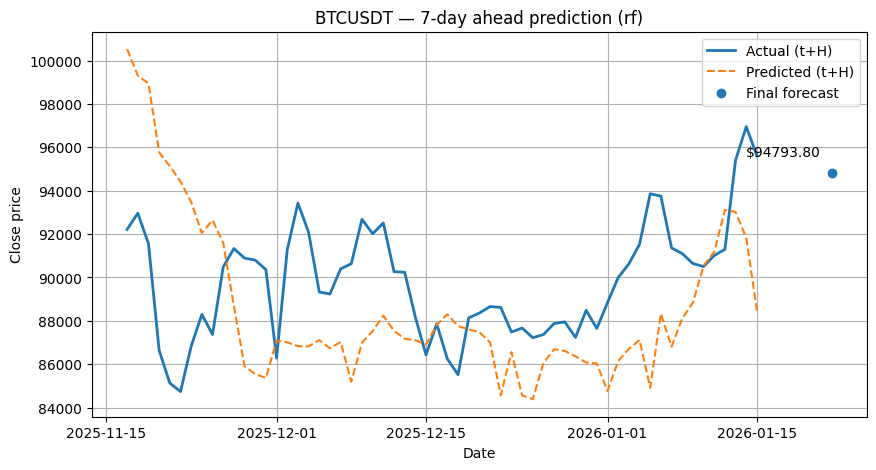


=== BNBUSDT | Best model: lr ===
Latest raw-date forecast (used for DB insert):
  last_date_used forecast_date  predicted_close model
0     2026-01-15    2026-01-22       956.154639    lr


<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$956.15')

Text(0.5, 1.0, 'BNBUSDT — 7-day ahead prediction (lr)')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

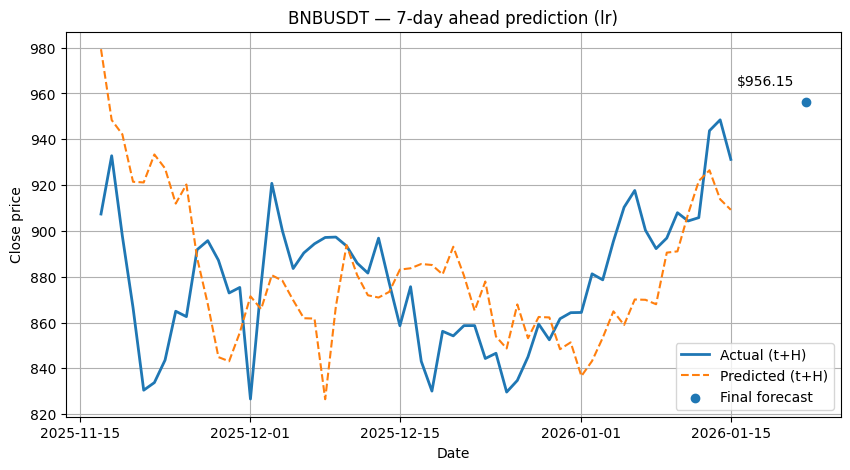


=== SOLUSDT | Best model: gbt ===
Latest raw-date forecast (used for DB insert):
  last_date_used forecast_date  predicted_close model
0     2026-01-15    2026-01-22       144.824266   gbt


<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$144.82')

Text(0.5, 1.0, 'SOLUSDT — 7-day ahead prediction (gbt)')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

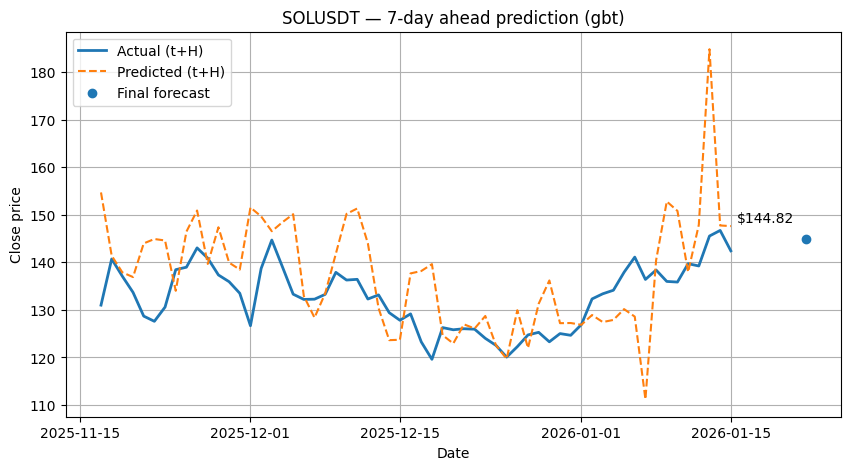


=== XRPUSDT | Best model: lr ===
Latest raw-date forecast (used for DB insert):
  last_date_used forecast_date  predicted_close model
0     2026-01-15    2026-01-22         2.143789    lr


<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$2.14')

Text(0.5, 1.0, 'XRPUSDT — 7-day ahead prediction (lr)')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

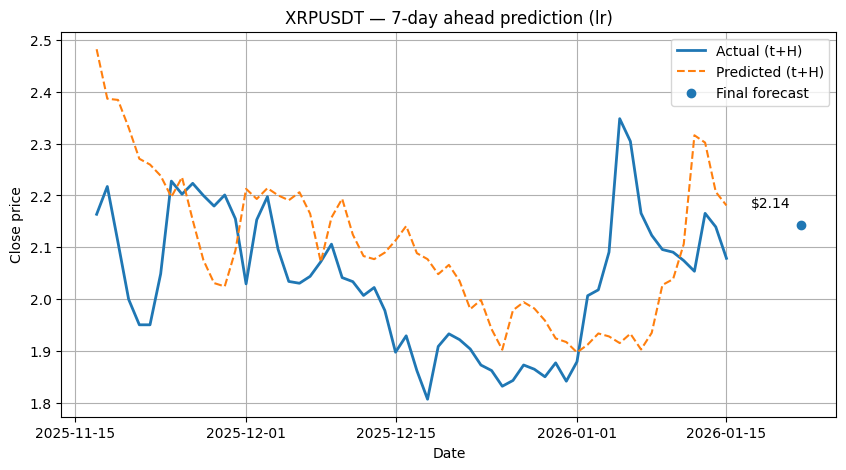


=== ETHUSDT | Best model: lr ===
Latest raw-date forecast (used for DB insert):
  last_date_used forecast_date  predicted_close model
0     2026-01-15    2026-01-22       3372.95263    lr


<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$3372.95')

Text(0.5, 1.0, 'ETHUSDT — 7-day ahead prediction (lr)')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

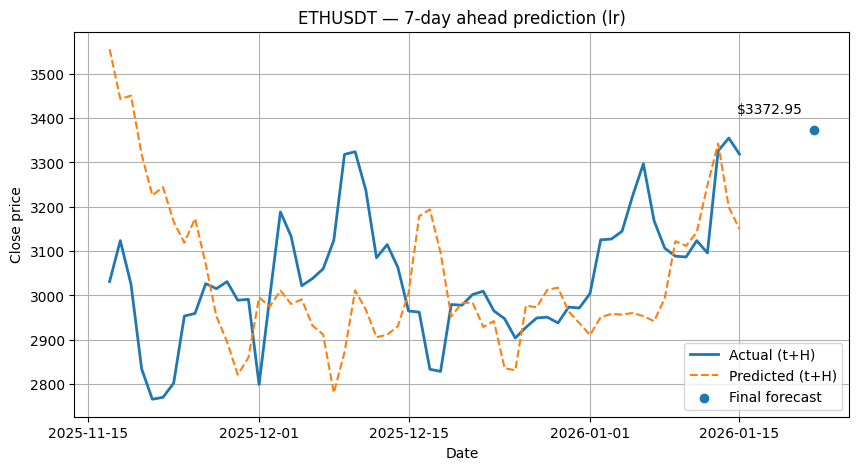

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.ml import Pipeline
from pyspark.sql.functions import col

assets = [r["asset"] for r in final_pred_df.select("asset").distinct().collect()]

for asset in assets:
    best_model_name = (
        best_models.filter(col("asset") == asset)
        .select("model").first()["model"]
    )

    pipe = Pipeline(stages=[assembler, model_map[best_model_name]])
    fitted = pipe.fit(train_df.filter(col("asset") == asset))

    # Test predictions
    preds = (
        fitted
        .transform(test_df.filter(col("asset") == asset))
        .select("date", "label", "prediction")
        .orderBy("date")
        .toPandas()
    )

    preds["date"] = pd.to_datetime(preds["date"])

    # Latest raw-date forecast (from final_pred_df)
    latest_forecast = (
        final_pred_df.filter(col("asset") == asset)
        .select("last_date_used", "forecast_date", "predicted_close", "model")
        .toPandas()
    )
    if not latest_forecast.empty:
        latest_forecast["last_date_used"] = pd.to_datetime(latest_forecast["last_date_used"])
        latest_forecast["forecast_date"] = pd.to_datetime(latest_forecast["forecast_date"])

    print(f"\n=== {asset} | Best model: {best_model_name} ===")
    if not latest_forecast.empty:
        print("Latest raw-date forecast (used for DB insert):")
        print(latest_forecast)



    preds["target_date"] = preds["date"] + pd.Timedelta(days=int(N_HORIZON))

    plt.figure(figsize=(10, 5))
    plt.plot(preds["target_date"], preds["label"], label="Actual (t+H)", linewidth=2)
    plt.plot(preds["target_date"], preds["prediction"], label="Predicted (t+H)", linestyle="--")

    # annotate the final forecast point (if present)
    if not latest_forecast.empty:
        x = latest_forecast.loc[0, "forecast_date"]
        y = float(latest_forecast.loc[0, "predicted_close"])
        plt.scatter([x], [y], marker="o", label="Final forecast")

        plt.annotate(
            f"${y:.2f}",
            (x, y),
            textcoords="offset points",
            xytext=(-8, 10),   # top-left
            ha="right",
            va="bottom"
        )

    plt.title(f"{asset} — {int(N_HORIZON)}-day ahead prediction ({best_model_name})")
    plt.xlabel("Date")
    plt.ylabel("Close price")

    plt.legend()
    plt.grid(True)
    plt.show()


# ARIMA baseline (per-asset) — 7-day ahead forecast

Generate foreacasts using an ARIMA model for each asset, serving as a baseline to compare against the regression models.

1. Loops though each asset and extracts the `date` and `close`, orders by date, and converts them to a DataFrame
2. Performs a grid serach over a range of parameters (p,d,q)
3. Fits an ARIMA model for each combination and selects the order with the lowest AIC
4. Predicts the 7 day ahead price using the best ARIMA model for each asset
5. Stores and displays results in **arima_pred_df** which can be unioned with **final_pred_df** for side by side comparison

In [ ]:
import warnings
from datetime import timedelta
from statsmodels.tsa.arima.model import ARIMA
from pyspark.sql.functions import col

# We'll produce the same schema as final_pred_df so it's easy to compare / union.
# Model field will include the chosen ARIMA order.
arima_predictions = []

assets = [r["asset"] for r in df.select("asset").distinct().collect()]

# Simple per-asset auto-calibration via small grid search on (p,d,q) using AIC.
# Keep this small to avoid very long runtimes.
P_RANGE = range(0, 4)   # 0..3
D_RANGE = range(0, 2)   # 0..1
Q_RANGE = range(0, 4)   # 0..3

warnings.filterwarnings("ignore")

for asset in assets:
    pdf = (
        df
        .select("asset", "date", "close")
        .filter(col("asset") == asset)
        .orderBy("date")
        .toPandas()
    )

    if pdf.empty:
        continue

    pdf["date"] = pd.to_datetime(pdf["date"])
    pdf = pdf.dropna(subset=["close"]).copy()
    y = pdf["close"].astype("float64").values

    last_date = pdf["date"].max().date()

    best_aic = np.inf
    best_order = None
    best_res = None

    # Lightweight grid search
    for p in P_RANGE:
        for d in D_RANGE:
            for q in Q_RANGE:
                try:
                    res = ARIMA(y, order=(p, d, q)).fit()
                    if np.isfinite(res.aic) and res.aic < best_aic:
                        best_aic = res.aic
                        best_order = (p, d, q)
                        best_res = res
                except Exception:
                    continue

    # If everything failed, fall back to last value
    if best_res is None:
        pred_7d = float(y[-1])
        model_tag = "arima_failed_last_value"
    else:
        fc = best_res.forecast(steps=N_HORIZON)
        pred_7d = float(fc[-1])
        model_tag = f"arima{best_order}"

    arima_predictions.append((
        asset,
        last_date,
        last_date + timedelta(days=N_HORIZON),
        pred_7d,
        model_tag
    ))

arima_pred_df = spark_session.createDataFrame(
    arima_predictions,
    ["asset", "last_date_used", "forecast_date", "predicted_close", "model"]
)

arima_pred_df.show(truncate=False)

# Optional: compare side-by-side with the ML model predictions
all_pred_df = final_pred_df.unionByName(arima_pred_df)
all_pred_df.orderBy("asset", "model").show(truncate=False)

+-------+--------------+-------------+-----------------+--------------+
|asset  |last_date_used|forecast_date|predicted_close  |model         |
+-------+--------------+-------------+-----------------+--------------+
|BTCUSDT|2026-01-15    |2026-01-22   |95604.8          |arima(0, 1, 0)|
|SOLUSDT|2026-01-15    |2026-01-22   |142.4            |arima(0, 1, 0)|
|ETHUSDT|2026-01-15    |2026-01-22   |3318.69          |arima(0, 1, 0)|
|BNBUSDT|2026-01-15    |2026-01-22   |932.295539796522 |arima(2, 1, 0)|
|XRPUSDT|2026-01-15    |2026-01-22   |2.081995869522084|arima(3, 1, 3)|
+-------+--------------+-------------+-----------------+--------------+

+-------+--------------+-------------+------------------+--------------+
|asset  |last_date_used|forecast_date|predicted_close   |model         |
+-------+--------------+-------------+------------------+--------------+
|BNBUSDT|2026-01-15    |2026-01-22   |932.295539796522  |arima(2, 1, 0)|
|BNBUSDT|2026-01-15    |2026-01-22   |956.1546386080131 |lr

# Store ARIMA Forecasts in MariaDB

Connect to MariaDB and store the ARIMA forecasts (**arima_pred_df**) into the `arima_forecasts` table. This keeps daily ARIMA runs persisted for reporting and downstream use.

1. Add metadata columns to **arima_pred_df**
   - `horizon_days` comes from `N_HORIZON`
   - `run_date` is today’s date (used to identify the run)
   - `updated_at` is the timestamp when the rows are written
2. Prevent duplicates for the same run
   - Connect to MariaDB with the `mariadb` Python client
   - Delete any existing rows in `arima_forecasts` where `run_date` and `horizon_days` match the current run
3. Insert the new ARIMA forecasts
   - Write `to_store_arima_df` to MariaDB using PySpark’s JDBC writer in **append** mode


In [ ]:
import os
import pyspark.sql.functions as F
from datetime import date
import mariadb

connection_host = "localhost"
connection_port = 3306
db_name = "mda2_project"
table_name_arima = "arima_forecasts"
user_name = "osbdet"
password = os.environ.get("MARIADB_PASSWORD", "")

run_date_str = date.today().isoformat()

to_store_arima_df = (arima_pred_df
    .withColumn("horizon_days", F.lit(int(N_HORIZON)))
    .withColumn("run_date", F.lit(run_date_str).cast("date"))
    .withColumn("updated_at", F.current_timestamp())
)

# 1) delete existing rows for this run_date (and horizon)
conn = mariadb.connect(
    user=user_name,
    password=password,
    host=connection_host,
    port=connection_port,
    database=db_name
)
cur = conn.cursor()
cur.execute(
    f"DELETE FROM {table_name_arima} WHERE run_date = ? AND horizon_days = ?",
    (run_date_str, int(N_HORIZON))
)
conn.commit()
cur.close()
conn.close()

# 2) append new rows
(to_store_arima_df.write.format("jdbc")
    .mode("append")
    .option("url", f"jdbc:mariadb://{connection_host}:{connection_port}/{db_name}")
    .option("dbtable", table_name_arima)
    .option("user", user_name)
    .option("password", password)
    .option("driver", "org.mariadb.jdbc.Driver")
    .save()
)


### Look at the data we've loaded into our table

In [ ]:
loaded_df = (spark_session.read.format("jdbc")
    .option("driver", "org.mariadb.jdbc.Driver")
    .option("url", f"jdbc:mariadb://{connection_host}:{connection_port}/{db_name}")
    .option("dbtable", table_name_arima)
    .option("user", user_name)
    .option("password", password)
    .load()
)

loaded_df.orderBy("asset", "forecast_date").show(truncate=False)


+-------+--------------+-------------+---------------+--------------+------------+----------+-------------------+
|asset  |last_date_used|forecast_date|predicted_close|model         |horizon_days|run_date  |updated_at         |
+-------+--------------+-------------+---------------+--------------+------------+----------+-------------------+
|BNBUSDT|2026-01-10    |2026-01-17   |905.86690738   |arima(3, 1, 0)|7           |2026-01-11|2026-01-11 21:39:27|
|BNBUSDT|2026-01-12    |2026-01-19   |905.78377611   |arima(3, 1, 0)|7           |2026-01-13|2026-01-13 17:55:13|
|BNBUSDT|2026-01-15    |2026-01-22   |932.29553980   |arima(2, 1, 0)|7           |2026-01-17|2026-01-17 03:06:20|
|BTCUSDT|2026-01-10    |2026-01-17   |90504.70000000 |arima(0, 1, 0)|7           |2026-01-11|2026-01-11 21:39:27|
|BTCUSDT|2026-01-12    |2026-01-19   |91283.25636300 |arima(0, 1, 1)|7           |2026-01-13|2026-01-13 17:55:13|
|BTCUSDT|2026-01-15    |2026-01-22   |95604.80000000 |arima(0, 1, 0)|7           |2026-0

# Plot OOS ARIMA vs Actual (t+H)

For each **asset**, run a rolling out-of-sample ARIMA backtest and plot **Actual close at (t+H)** vs **Predicted (t+H)**, aligned on the **target date** (`t + H`).

1. Load asset history (`df`) and build the close series `y`
2. Read the final forecast point from `arima_pred_df` (`forecast_date`, `predicted_close`, `model`)
3. Parse ARIMA order `(p,d,q)` from `model` (fallback to `(0,1,0)`)
4. Create OOS targets: `actual_t_plus_h = close.shift(-H)`
5. Rolling backtest (last `TEST_POINTS`, after `MIN_TRAIN`):
   - fit ARIMA on data up to `t`
   - forecast `H` steps ahead → `pred_t_plus_h`
6. Plot last `LOOKBACK_DAYS` using `target_date = t_date + H days`, plus the final forecast point

This code implements out-of-sample (OOS) evaluation by re-fitting ARIMA at each time step using only past data up to t, then forecasting H days ahead and comparing the prediction to the true close at t+H (walk-forward backtest).


<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$95604.80')

(np.float64(20409.0), np.float64(20477.0))

Text(0.5, 1.0, 'BTCUSDT — 7-day ahead ARIMA (OOS) (arima(0, 1, 0))')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

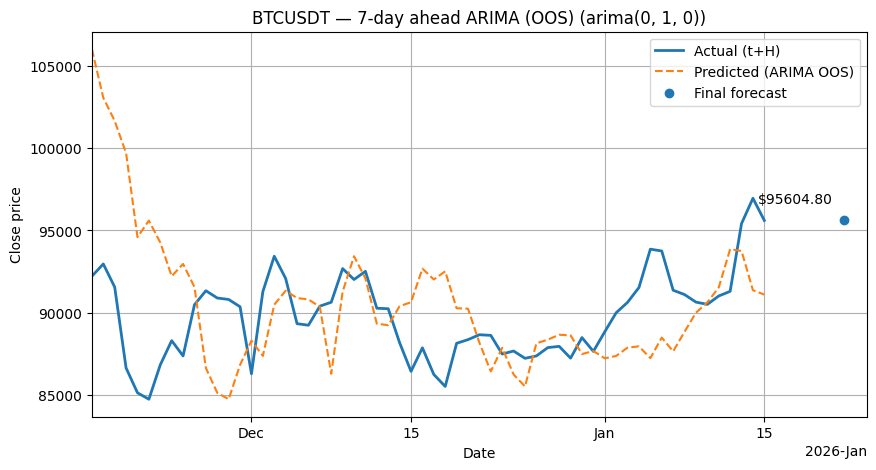

<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$142.40')

(np.float64(20409.0), np.float64(20477.0))

Text(0.5, 1.0, 'SOLUSDT — 7-day ahead ARIMA (OOS) (arima(0, 1, 0))')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

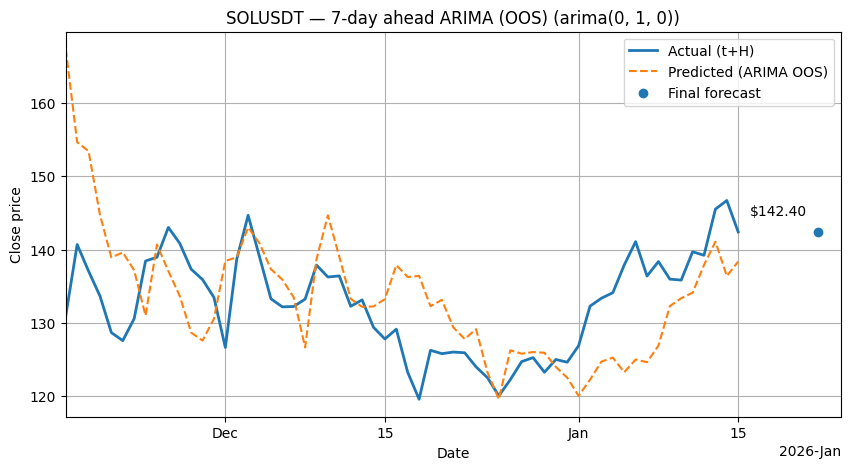

<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$932.30')

(np.float64(20409.0), np.float64(20477.0))

Text(0.5, 1.0, 'BNBUSDT — 7-day ahead ARIMA (OOS) (arima(2, 1, 0))')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

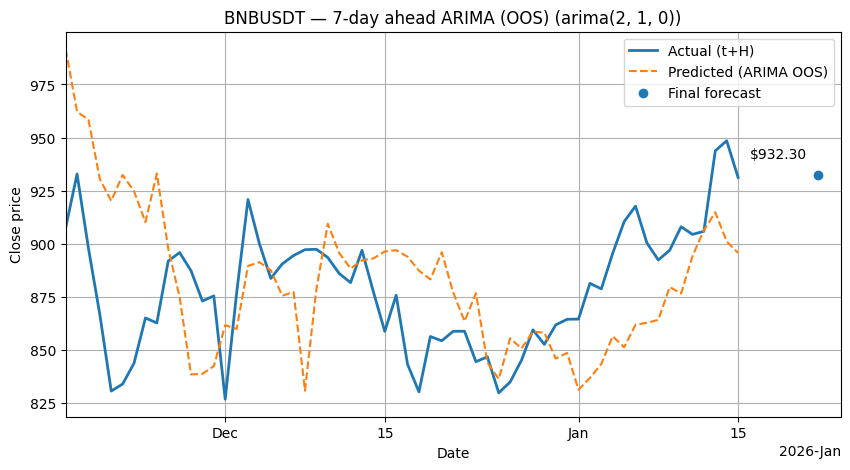

<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$2.08')

(np.float64(20409.0), np.float64(20477.0))

Text(0.5, 1.0, 'XRPUSDT — 7-day ahead ARIMA (OOS) (arima(3, 1, 3))')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

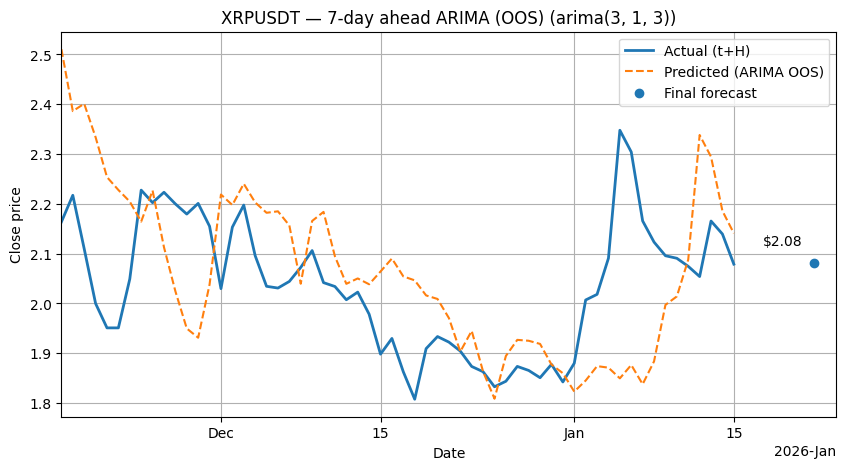

<Figure size 1000x500 with 0 Axes>

Text(-8, 10, '$3318.69')

(np.float64(20409.0), np.float64(20477.0))

Text(0.5, 1.0, 'ETHUSDT — 7-day ahead ARIMA (OOS) (arima(0, 1, 0))')

Text(0.5, 0, 'Date')

Text(0, 0.5, 'Close price')

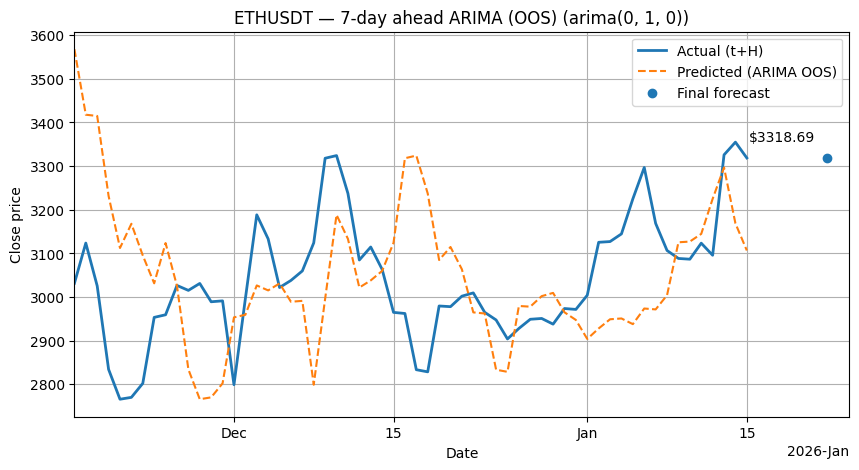

In [ ]:
import matplotlib.dates as mdates

LOOKBACK_DAYS = 90
TEST_POINTS = 60
MIN_TRAIN = 60

H = int(N_HORIZON)

assets = [r["asset"] for r in arima_pred_df.select("asset").distinct().collect()]

for asset in assets:
    # 1) history
    hist = (
        df.filter(col("asset") == asset)
          .select("date", "close")
          .orderBy("date")
          .toPandas()
    )
    if hist.empty:
        continue

    hist["date"] = pd.to_datetime(hist["date"])
    hist = hist.dropna(subset=["close"]).reset_index(drop=True)
    y = hist["close"].astype("float64").values

    # 2) final forecast point (already computed elsewhere)
    fc_row = (
        arima_pred_df.filter(col("asset") == asset)
        .select("forecast_date", "predicted_close", "model")
        .toPandas()
    )
    if fc_row.empty:
        continue

    fc_row["forecast_date"] = pd.to_datetime(fc_row["forecast_date"])
    x_fc = fc_row.loc[0, "forecast_date"]
    y_fc = float(fc_row.loc[0, "predicted_close"])
    model_tag = fc_row.loc[0, "model"]

    # 3) parse ARIMA order from "arima(p, d, q)"
    order = (0, 1, 0)
    try:
        if isinstance(model_tag, str) and model_tag.startswith("arima(") and model_tag.endswith(")"):
            order = tuple(int(x.strip()) for x in model_tag[6:-1].split(","))
    except Exception:
        order = (0, 1, 0)

    # 4) build OOS frame: feature date t, target value is close at t+H
    oos = pd.DataFrame({
        "t_date": hist["date"],
        "actual_t_plus_h": hist["close"].shift(-H)
    }).dropna().reset_index(drop=True)

    n_oos = len(oos)
    if n_oos <= MIN_TRAIN:
        print(f"{asset}: not enough data for OOS ARIMA (need > {MIN_TRAIN}, have {n_oos}).")
        continue

    start_idx = max(MIN_TRAIN, n_oos - TEST_POINTS)

    preds = []
    for t in range(start_idx, n_oos):
        y_train = y[:t + 1]  # train up to t (past only)
        try:
            res = ARIMA(y_train, order=order).fit()
            y_hat = float(res.forecast(steps=H)[-1])  # H-step ahead
        except Exception:
            y_hat = np.nan
        preds.append(y_hat)

    oos_eval = oos.iloc[start_idx:].copy()
    oos_eval["pred_t_plus_h"] = preds

    # align plot x-axis to the target date (t+H)
    oos_eval["target_date"] = oos_eval["t_date"] + pd.Timedelta(days=H)

    # zoom based on target_date
    max_target = oos_eval["target_date"].max()
    min_zoom = max_target - pd.Timedelta(days=LOOKBACK_DAYS)
    z = oos_eval[oos_eval["target_date"] >= min_zoom].copy()

    plt.figure(figsize=(10, 5))
    plt.plot(z["target_date"], z["actual_t_plus_h"], label="Actual (t+H)", linewidth=2)

    if z["pred_t_plus_h"].notna().any():
        plt.plot(z["target_date"], z["pred_t_plus_h"], label="Predicted (ARIMA OOS)", linestyle="--")

    # final forecast point is already on forecast_date (target date)
    plt.scatter([x_fc], [y_fc], marker="o", label="Final forecast")
    plt.annotate(
        f"${y_fc:.2f}",
        (x_fc, y_fc),
        textcoords="offset points",
        xytext=(-8, 10),
        ha="right",
        va="bottom"
    )

    plt.xlim(z["target_date"].min(), max(z["target_date"].max(), x_fc) + pd.Timedelta(days=2))
    plt.title(f"{asset} — {H}-day ahead ARIMA (OOS) ({model_tag})")
    plt.xlabel("Date")
    plt.ylabel("Close price")
    plt.legend();  # semicolon hides Legend object in notebook output
    plt.grid(True)

    # helps render the dates
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

    plt.show()
